<a href="https://colab.research.google.com/github/sofilukash/math_modeling/blob/main/lab1/task2_mikhailov.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 1. Завдання 2
## Годограф Михайлова — дослідження стійкості (варіант 3)

**Варіант 3:** $D(p)=p^{10}+7p^{8}+11p^{7}+5p+1$

**Критерій Михайлова.** Підставляємо $p=i\omega$: $D(i\omega)=X(\omega)+iY(\omega)$.
Лінійна система $n$-го порядку **стійка** тоді й лише тоді, коли при зміні $\omega$ від $0$ до $+\infty$
приріст аргументу $\Delta\arg D(i\omega)=n\pi/2$, тобто годограф послідовно проходить $n$ квадрантів
**проти годинникової стрілки**, не проходячи через початок координат.

**Як перевіряємо в програмі (3 незалежні способи):**
1. чисельно рахуємо $\Delta\arg D(i\omega)$ (з розгорткою фази `np.unwrap`) і порівнюємо з $n\pi/2$;
2. рахуємо послідовність квадрантів, які проходить годограф;
3. знаходимо корені $D(p)=0$ (`np.roots`): система стійка, якщо всі $\mathrm{Re}\,p_k<0$.
   Зв'язок: $\Delta\arg=(n-2k)\,\pi/2$, де $k$ — кількість коренів у правій півплощині.

Додатково: необхідна умова стійкості — **усі коефіцієнти додатні** (в нашому $D(p)$ частина коефіцієнтів
дорівнює нулю — це вже ознака нестійкості).

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy import signal

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
SAVE_DIR = "results"
os.makedirs(SAVE_DIR, exist_ok=True)


def poly_to_str(c):
    """Вивести поліном зі списку коефіцієнтів (від старшого степеня до молодшого)."""
    n = len(c) - 1
    parts = []
    for i, a in enumerate(c):
        deg = n - i
        if a == 0:
            continue
        coef = "" if (a == 1 and deg > 0) else f"{a:g}"
        var = "" if deg == 0 else ("p" if deg == 1 else f"p^{deg}")
        parts.append(coef + var)
    return " + ".join(parts)

## Функція аналізу
`mikhailov(coeffs, ...)` будує годограф і виконує всі три перевірки.
Коефіцієнти задаються **від старшого степеня до молодшого** (у `np.roots`/`np.polyval` так само).

In [7]:
def mikhailov(coeffs, name, filename, zoom=None):
    c = np.array(coeffs, dtype=float)
    n = len(c) - 1
    print("=" * 78)
    print(f"{name}:  D(p) = {poly_to_str(coeffs)},   порядок n = {n}")
    print("=" * 78)

    # --- 0. Необхідна умова: всі коефіцієнти додатні ---
    all_pos = bool(np.all(c > 0))
    print(f"Необхідна умова (усі коефіцієнти > 0): {'виконується' if all_pos else 'НЕ виконується'}")

    # --- 1. Корені характеристичного полінома ---
    roots = np.roots(c)
    k_rhp = int(np.sum(roots.real > 1e-9))
    max_re = roots.real.max()
    print(f"Корені: найбільша Re(p) = {max_re:+.4f};  коренів у правій півплощині k = {k_rhp} з {n}")

    # --- 2. Годограф D(iω) ---
    # Сітка по ω: густа лінійна до 2R та логарифмічна далі (щоб Δarg вийшло на асимптоту nπ/2)
    R = max(1.0, np.max(np.abs(roots)))
    w = np.concatenate([np.linspace(0, 2 * R, 200001), np.geomspace(2 * R, 1e4 * R, 40000)[1:]])
    D = np.polyval(c, 1j * w)                      # D(iω) = X + iY
    X, Y = D.real, D.imag

    # Перехресна перевірка через scipy: signal.freqs(b, a=[1]) повертає B(iω)/1 = D(iω)
    _, D_scipy = signal.freqs(c, [1.0], worN=w[:5000])
    assert np.allclose(D[:5000], D_scipy, rtol=1e-9), "polyval і scipy.signal.freqs розходяться"

    # --- 3. Приріст аргументу ---
    arg = np.unwrap(np.angle(D))                   # неперервна гілка аргументу
    d_arg = arg[-1] - arg[0]
    ratio = d_arg / (np.pi / 2)                    # у одиницях π/2: має бути n для стійкої системи
    print(f"Δarg D(iω), ω: 0→∞  =  {ratio:.3f} · π/2     (еталон для стійкої системи: n = {n})")
    print(f"Незалежна перевірка за коренями: (n − 2k) = {n - 2 * k_rhp}")
    assert abs(ratio - (n - 2 * k_rhp)) < 0.1, "Δarg не збігся з (n−2k) — перевірте розрахунок"

    # --- 4. Послідовність квадрантів ---
    eps = 1e-9 * np.abs(D)                         # допуск відносно |D| у кожній точці
    quad = np.zeros(len(w), dtype=int)
    quad[(X > eps) & (Y > eps)] = 1
    quad[(X < -eps) & (Y > eps)] = 2
    quad[(X < -eps) & (Y < -eps)] = 3
    quad[(X > eps) & (Y < -eps)] = 4
    q = quad[quad > 0]
    q = q[np.insert(np.diff(q) != 0, 0, True)]     # стискаємо повтори
    steps = np.diff(q) % 4
    ccw, cw = int(np.sum(steps == 1)), int(np.sum(steps == 3))
    print("Квадранти (за порядком проходження): " + " → ".join(map(str, q)))
    print(f"Переходів проти годинникової: {ccw}, за годинниковою: {cw}, через квадрант: {int(np.sum(steps == 2))}")

    # --- 5. Висновок ---
    stable = (abs(ratio - n) < 0.1) and k_rhp == 0 and all_pos
    if stable:
        verdict = "СТІЙКА (годограф проходить n квадрантів проти годинникової стрілки)"
    else:
        verdict = f"НЕСТІЙКА (Δarg = {ratio:.2f}·π/2 ≠ n·π/2 = {n}·π/2;  k = {k_rhp} коренів у правій півплощині)"
    print(f"\nВИСНОВОК: система {verdict}\n")

    # ------------------------- Малюнок -------------------------
    fig, axs = plt.subplots(2, 2, figsize=(13, 10))

    # (а) годограф у природному масштабі: ω від 0 до 1.3 R
    sel = np.where(w <= 1.3 * R)[0][::40]            # проріджуємо точки лише для малювання (швидкість)
    ax = axs[0, 0]
    pts = np.column_stack([X[sel], Y[sel]]).reshape(-1, 1, 2)
    lc = LineCollection(np.concatenate([pts[:-1], pts[1:]], axis=1), cmap="viridis",
                        norm=plt.Normalize(0, w[sel].max()))
    lc.set_array(w[sel][:-1])
    lc.set_linewidth(1.8)
    # symlog: поблизу нуля шкала лінійна, далі логарифмічна. Знаки X, Y зберігаються,
    # тому квадранти та напрям обходу видно так само, а дуже великі значення D не «розтягують» малюнок.
    lt = 10 * max(abs(c[-1]), 1.0)
    ax.set_xscale("symlog", linthresh=lt)
    ax.set_yscale("symlog", linthresh=lt)
    ax.add_collection(lc)
    ax.autoscale_view()
    ax.plot(X[0], Y[0], "go", label="ω = 0")
    ax.axhline(0, color="k", lw=0.8)
    ax.axvline(0, color="k", lw=0.8)
    ax.plot(0, 0, "r*", ms=12, label="початок координат")
    ax.set_title(r"Годограф Михайлова $D(i\omega)$, $\omega\in[0,\,1.3R]$ (шкала symlog)")
    ax.set_xlabel("X(ω) = Re D(iω)")
    ax.set_ylabel("Y(ω) = Im D(iω)")
    ax.legend(loc="best", fontsize=9)
    fig.colorbar(lc, ax=ax, label="ω")

    # (б) збільшений фрагмент біля початку координат
    ax = axs[0, 1]
    L = zoom if zoom is not None else 6 * max(abs(c[-1]), 1.0)
    near = np.hypot(X, Y) < 40 * L
    ax.plot(X[near & (w <= 1.3 * R)], Y[near & (w <= 1.3 * R)], lw=1.8, color="tab:blue")
    ax.plot(X[0], Y[0], "go")
    ax.plot(0, 0, "r*", ms=12)
    ax.axhline(0, color="k", lw=0.8)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlim(-L, L)
    ax.set_ylim(-L, L)
    ax.set_title("Збільшений фрагмент біля початку координат")
    ax.set_xlabel("X(ω)")
    ax.set_ylabel("Y(ω)")

    # (в) аргумент: arg D(iω) / (π/2) проти ω
    ax = axs[1, 0]
    ax.semilogx(w[1:], arg[1:] / (np.pi / 2), lw=1.8)
    ax.axhline(n, color="g", ls="--", label=f"n = {n} (стійка система)")
    ax.axhline(ratio, color="r", ls=":", label=f"фактично {ratio:.2f}")
    ax.set_title(r"Приріст аргументу $\arg D(i\omega)$ в одиницях $\pi/2$")
    ax.set_xlabel("ω (логарифмічна шкала)")
    ax.set_ylabel(r"$\arg D / (\pi/2)$")
    ax.legend(loc="best")

    # (г) корені на комплексній площині
    ax = axs[1, 1]
    colors = np.where(roots.real < 0, "tab:green", "tab:red")
    ax.scatter(roots.real, roots.imag, c=colors, s=60, zorder=3)
    ax.axhline(0, color="k", lw=0.8)
    ax.axvline(0, color="k", lw=0.8)
    ax.axvspan(0, max(1, roots.real.max() * 1.3), color="red", alpha=0.08)
    ax.set_title("Корені D(p): зелені — Re<0 (стійкі), червоні — Re>0 (нестійкі)")
    ax.set_xlabel("Re p")
    ax.set_ylabel("Im p")
    ax.set_aspect("equal", adjustable="datalim")

    fig.suptitle(f"{name}:  D(p) = {poly_to_str(coeffs)}\nВисновок: {'СТІЙКА' if stable else 'НЕСТІЙКА'}",
                 fontsize=12)
    fig.tight_layout()
    path = os.path.join(SAVE_DIR, filename)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"[збережено] {path}")
    plt.show()
    return dict(name=name, n=n, ratio=ratio, k=k_rhp, stable=stable)

## 1. Індивідуальний варіант 3
$D(p)=p^{10}+7p^8+11p^7+5p+1$ — коефіцієнти при $p^9,\,p^6,\,p^5,\,p^4,\,p^3,\,p^2$ нульові.

Варіант 3:  D(p) = p^10 + 7p^8 + 11p^7 + 5p + 1,   порядок n = 10
Необхідна умова (усі коефіцієнти > 0): НЕ виконується
Корені: найбільша Re(p) = +0.7514;  коренів у правій півплощині k = 6 з 10
Δarg D(iω), ω: 0→∞  =  -2.000 · π/2     (еталон для стійкої системи: n = 10)
Незалежна перевірка за коренями: (n − 2k) = -2
Квадранти (за порядком проходження): 1 → 4 → 3
Переходів проти годинникової: 0, за годинниковою: 2, через квадрант: 0

ВИСНОВОК: система НЕСТІЙКА (Δarg = -2.00·π/2 ≠ n·π/2 = 10·π/2;  k = 6 коренів у правій півплощині)

[збережено] results/fig6_mikhailov_variant3.png


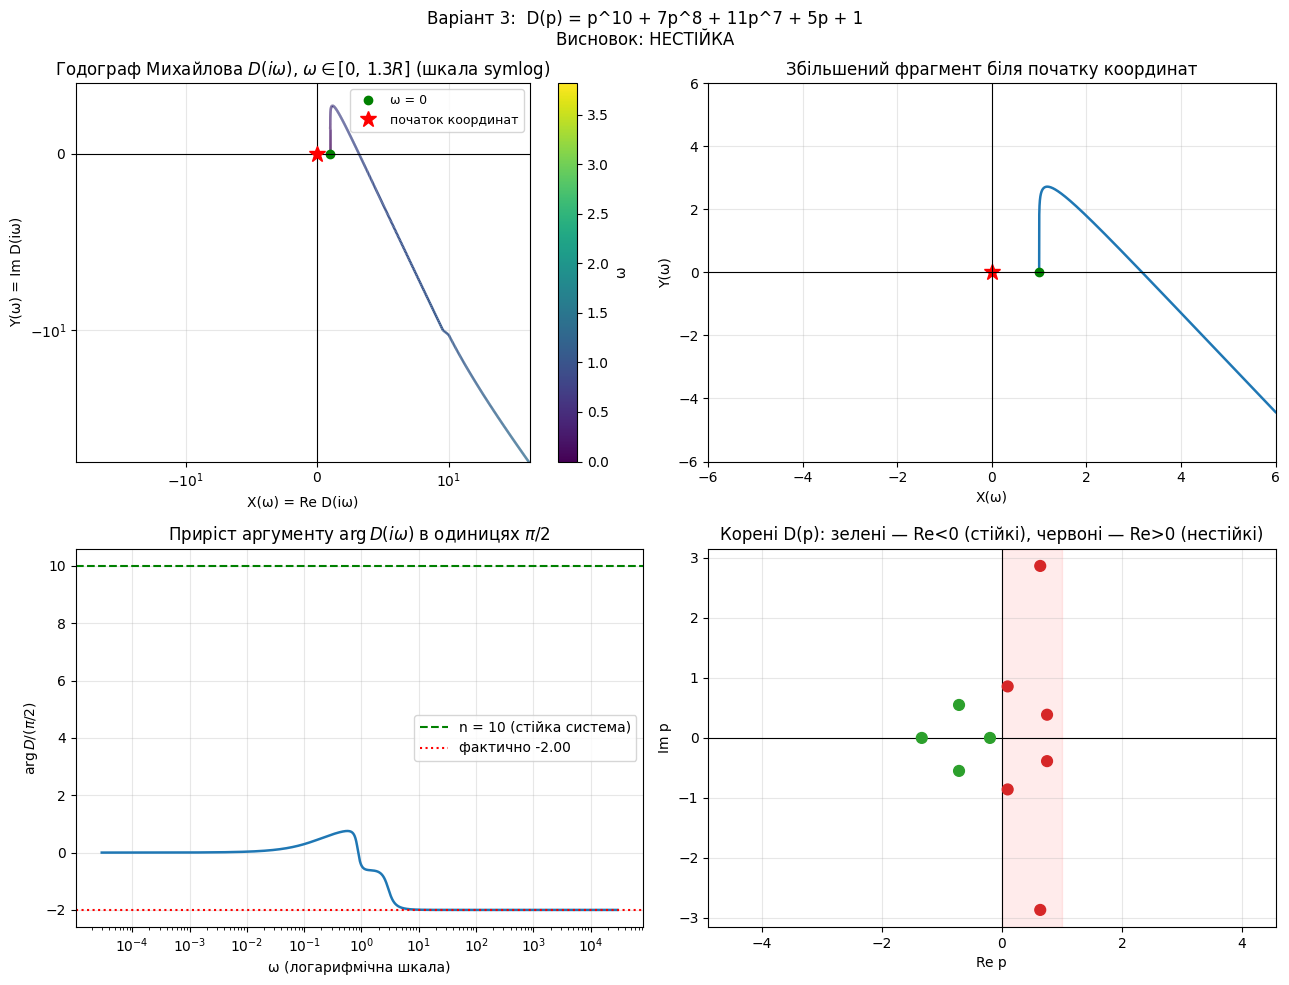

In [8]:
#            p^10 p^9 p^8 p^7 p^6 p^5 p^4 p^3 p^2 p^1 p^0
VARIANT_3 = [1,   0,  7, 11,  0,  0,  0,  0,  0,  5,  1]
res_var = mikhailov(VARIANT_3, "Варіант 3", "fig6_mikhailov_variant3.png")

## 2. Перевірка алгоритму на стійкій системі (контрольне питання 1.5.2)
$D(p)=(p+1)(p+2)(p+3)=p^3+6p^2+11p+6$ — корені $-1,-2,-3$, порядок $n=3$.
Очікуємо: $\Delta\arg=3\pi/2$, годограф проходить 3 квадранти проти годинникової стрілки.
Для наочності — ще система 4-го порядку $(p+1)(p+2)(p+3)(p+4)=p^4+10p^3+35p^2+50p+24$.

Стійкий приклад n=3:  D(p) = p^3 + 6p^2 + 11p + 6,   порядок n = 3
Необхідна умова (усі коефіцієнти > 0): виконується
Корені: найбільша Re(p) = -1.0000;  коренів у правій півплощині k = 0 з 3
Δarg D(iω), ω: 0→∞  =  3.000 · π/2     (еталон для стійкої системи: n = 3)
Незалежна перевірка за коренями: (n − 2k) = 3
Квадранти (за порядком проходження): 1 → 2 → 3
Переходів проти годинникової: 2, за годинниковою: 0, через квадрант: 0

ВИСНОВОК: система СТІЙКА (годограф проходить n квадрантів проти годинникової стрілки)

[збережено] results/fig7_mikhailov_stable_n3.png


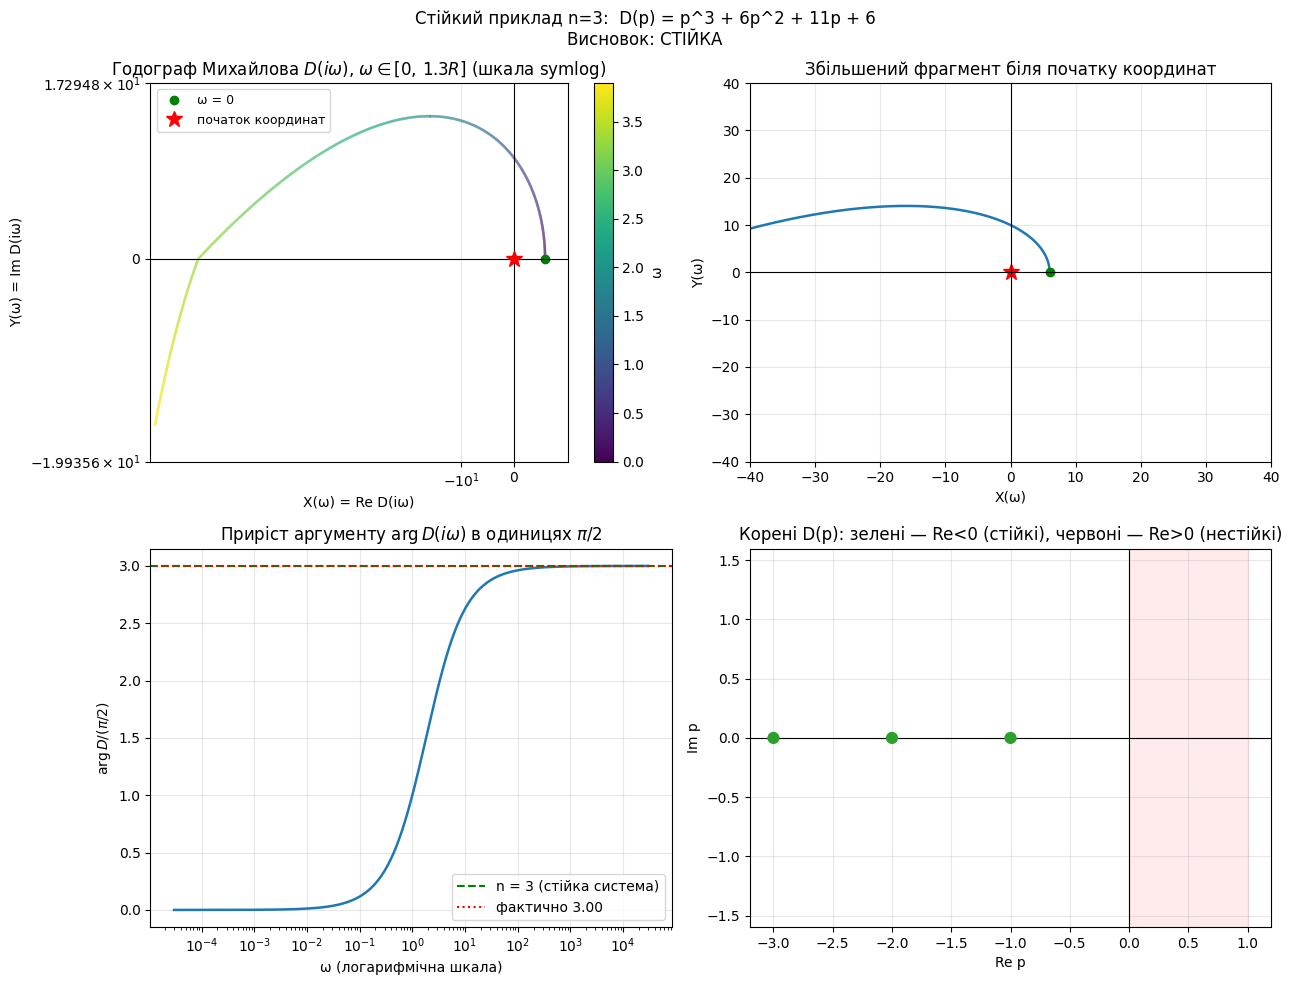

Стійкий приклад n=4:  D(p) = p^4 + 10p^3 + 35p^2 + 50p + 24,   порядок n = 4
Необхідна умова (усі коефіцієнти > 0): виконується
Корені: найбільша Re(p) = -1.0000;  коренів у правій півплощині k = 0 з 4
Δarg D(iω), ω: 0→∞  =  4.000 · π/2     (еталон для стійкої системи: n = 4)
Незалежна перевірка за коренями: (n − 2k) = 4
Квадранти (за порядком проходження): 1 → 2 → 3 → 4
Переходів проти годинникової: 3, за годинниковою: 0, через квадрант: 0

ВИСНОВОК: система СТІЙКА (годограф проходить n квадрантів проти годинникової стрілки)

[збережено] results/fig8_mikhailov_stable_n4.png


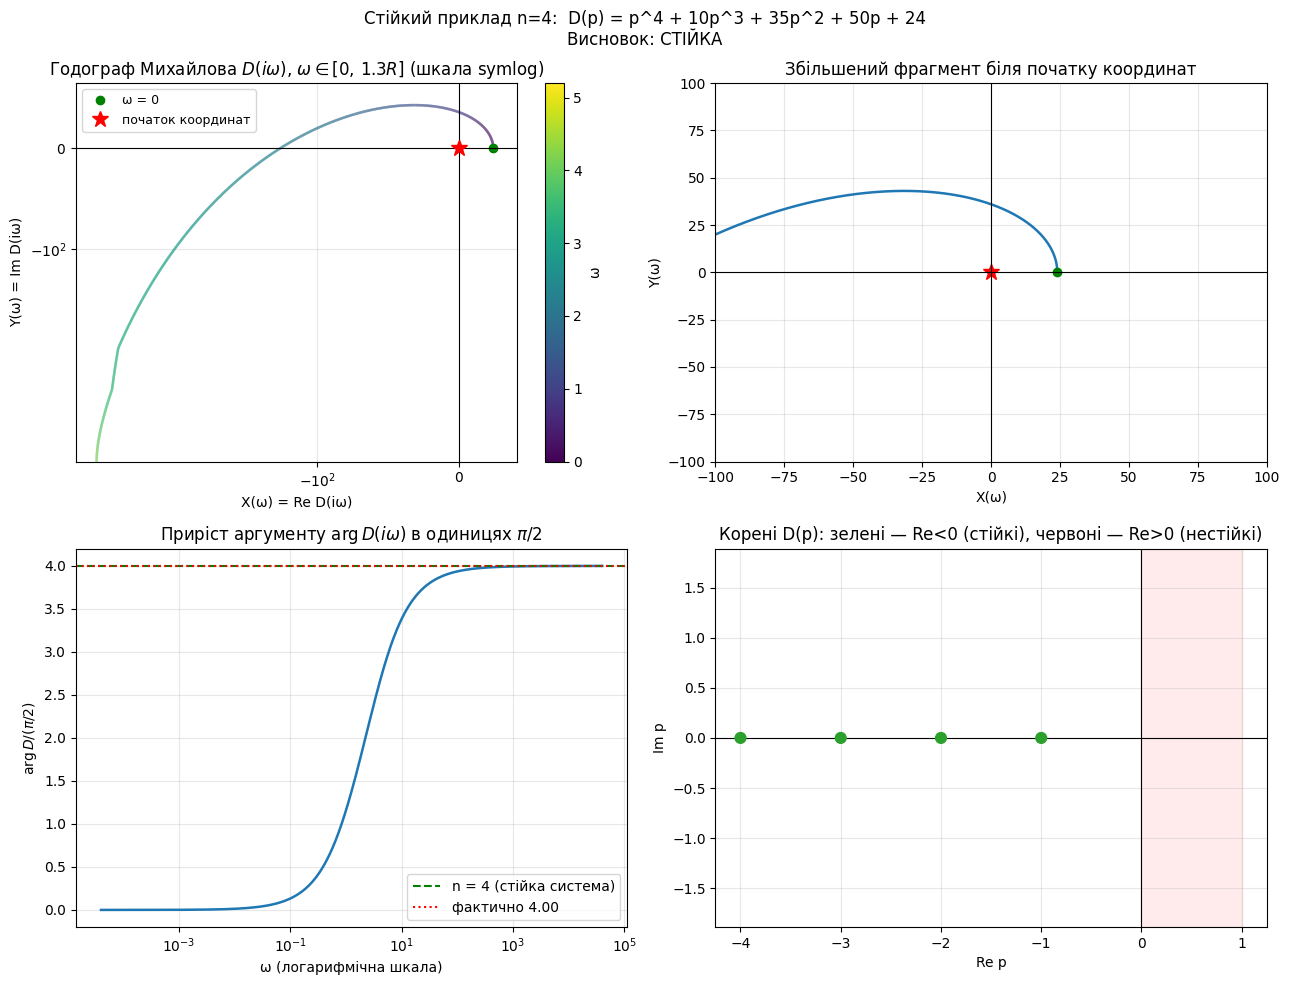

In [9]:
res_ex3 = mikhailov([1, 6, 11, 6], "Стійкий приклад n=3", "fig7_mikhailov_stable_n3.png", zoom=40)
res_ex4 = mikhailov([1, 10, 35, 50, 24], "Стійкий приклад n=4", "fig8_mikhailov_stable_n4.png", zoom=100)

## Підсумок

In [10]:
print(f"{'Система':<24}{'n':>3}{'Δarg/(π/2)':>13}{'k (Re>0)':>10}   результат")
print("-" * 62)
for r in (res_var, res_ex3, res_ex4):
    print(f"{r['name']:<24}{r['n']:>3}{r['ratio']:>13.2f}{r['k']:>10}   {'стійка' if r['stable'] else 'НЕСТІЙКА'}")

Система                   n   Δarg/(π/2)  k (Re>0)   результат
--------------------------------------------------------------
Варіант 3                10        -2.00         6   НЕСТІЙКА
Стійкий приклад n=3       3         3.00         0   стійка
Стійкий приклад n=4       4         4.00         0   стійка


## Висновки (завдання 2)

* Для **варіанта 3** $D(p)=p^{10}+7p^8+11p^7+5p+1$ необхідна умова не виконується (є нульові коефіцієнти),
  а годограф Михайлова **не набирає приросту аргументу $n\pi/2=5\pi$**: він не проходить 10 квадрантів
  послідовно проти годинникової стрілки. Різниця $n-\Delta\arg/(\pi/2)=2k$ збігається з числом коренів у
  правій півплощині (перевірено через `np.roots`). **Система нестійка.**
* На прикладах $(p+1)(p+2)(p+3)$ та $(p+1)\dots(p+4)$ програма дає $\Delta\arg=n\pi/2$, годограф
  проходить $n$ квадрантів проти годинникової стрілки — **системи стійкі**, що підтверджує коректність програми.
* **Контрольне питання 1.5.2:** приклад стійкої системи 3-го порядку — $p^3+6p^2+11p+6=0$ (корені $-1,-2,-3$),
  її годограф див. `fig7_mikhailov_stable_n3.png`.